In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


In [2]:
df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())


Dataset Shape: (1000, 16)

First 5 Records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

In [3]:
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["Heart Disease"].value_counts())



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age                      1000 non-null   int64
 1   Gender                   1000 non-null   str  
 2   Cholesterol              1000 non-null   int64
 3   Blood Pressure           1000 non-null   int64
 4   Heart Rate               1000 non-null   int64
 5   Smoking                  1000 non-null   str  
 6   Alcohol Intake           660 non-null    str  
 7   Exercise Hours           1000 non-null   int64
 8   Family History           1000 non-null   str  
 9   Diabetes                 1000 non-null   str  
 10  Obesity                  1000 non-null   str  
 11  Stress Level             1000 non-null   int64
 12  Blood Sugar              1000 non-null   int64
 13  Exercise Induced Angina  1000 non-null   str  
 14  Chest Pain Type          1000 non-null   str  

In [4]:
X = df.drop("Heart Disease", axis=1)

y = df["Heart Disease"]

In [5]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))


Numerical Features:
['Age', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Exercise Hours', 'Stress Level', 'Blood Sugar']

Categorical Features:
['Gender', 'Smoking', 'Alcohol Intake', 'Family History', 'Diabetes', 'Obesity', 'Exercise Induced Angina', 'Chest Pain Type']


C:\Users\acer\AppData\Local\Temp\ipykernel_11260\892563665.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data: (800, 15)
Testing Data : (200, 15)


In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [8]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


In [9]:
K = 5
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_train_processed,
    y_train
)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [10]:
y_pred = knn.predict(
    X_test_processed
)

print("Predicted Values:")
print(y_pred[:20])

print(
    classification_report(
        y_test,
        y_pred
    )
)


Predicted Values:
[1 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 0 0 1]
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       122
           1       0.80      0.85      0.82        78

    accuracy                           0.86       200
   macro avg       0.85      0.86      0.85       200
weighted avg       0.86      0.86      0.86       200



In [11]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

accuracy_values = []
precision_values = []
recall_values = []
f1_values = []

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(
        X_train_processed,
        y_train
    )

    y_pred = knn.predict(
        X_test_processed
    )

    accuracy_values.append(
        accuracy_score(
            y_test,
            y_pred
        )
    )

    precision_values.append(
        precision_score(
            y_test,
            y_pred
        )
    )

    recall_values.append(
        recall_score(
            y_test,
            y_pred
        )
    )

    f1_values.append(
        f1_score(
            y_test,
            y_pred
        )
    )


results = pd.DataFrame({
    "K": k_values,
    "Accuracy": accuracy_values,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1 Score": f1_values
})

print(results)


    K  Accuracy  Precision    Recall  F1 Score
0   1     0.795   0.740260  0.730769  0.735484
1   3     0.885   0.866667  0.833333  0.849673
2   5     0.860   0.804878  0.846154  0.825000
3   7     0.885   0.866667  0.833333  0.849673
4   9     0.875   0.853333  0.820513  0.836601
5  11     0.905   0.915493  0.833333  0.872483
6  15     0.900   0.902778  0.833333  0.866667
7  21     0.900   0.902778  0.833333  0.866667


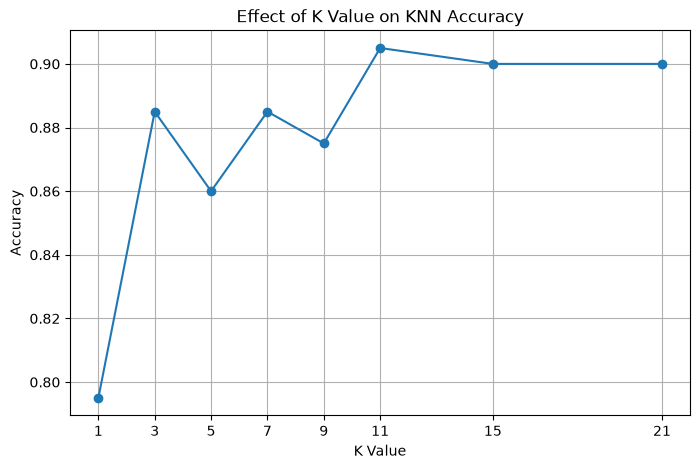

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracy_values,
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")

plt.title("Effect of K Value on KNN Accuracy")

plt.xticks(k_values)

plt.grid()

plt.show()

In [13]:
best_index = np.argmax(f1_values)

best_k = k_values[best_index]

print("Best K:", best_k)

print(
    "Best Accuracy:",
    accuracy_values[best_index]
)

print(
    "Best Precision:",
    precision_values[best_index]
)

print(
    "Best Recall:",
    recall_values[best_index]
)

print(
    "Best F1 Score:",
    f1_values[best_index]
)


# In[22]:


final_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_knn.fit(
    X_train_processed,
    y_train
)

final_pred = final_knn.predict(
    X_test_processed
)


Best K: 11
Best Accuracy: 0.905
Best Precision: 0.9154929577464789
Best Recall: 0.8333333333333334
Best F1 Score: 0.87248322147651


In [14]:
final_accuracy = accuracy_score(
    y_test,
    final_pred
)

final_precision = precision_score(
    y_test,
    final_pred
)

final_recall = recall_score(
    y_test,
    final_pred
)

final_f1 = f1_score(
    y_test,
    final_pred
)

final_cm = confusion_matrix(
    y_test,
    final_pred
)

TN, FP, FN, TP = final_cm.ravel()

final_specificity = TN / (TN + FP)

final_probability = final_knn.predict_proba(
    X_test_processed
)[:, 1]

final_auc = roc_auc_score(
    y_test,
    final_probability
)

print("\n======================================")
print("FINAL KNN MODEL")
print("======================================")

print("Best K       :", best_k)
print("Accuracy     :", final_accuracy)
print("Precision    :", final_precision)
print("Recall       :", final_recall)
print("F1 Score     :", final_f1)
print("Specificity  :", final_specificity)
print("AUC          :", final_auc)


FINAL KNN MODEL
Best K       : 11
Accuracy     : 0.905
Precision    : 0.9154929577464789
Recall       : 0.8333333333333334
F1 Score     : 0.87248322147651
Specificity  : 0.9508196721311475
AUC          : 0.9550756620428752
